## **Stage 1: Getting the data ready and EDA (Exploaratory data analysis)**

In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]
Python executable: C:\Users\HP\miniconda3\envs\dog-vision\python.exe


In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
import datasets

print("Datasets library version:", datasets.__version__)

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Datasets library version: 5.1.0


### **Load our dataset**

In [4]:
from datasets import load_dataset

# Load the email spam dataset
email_dataset = load_dataset("diegovelilla/email-classification-dataset")

'_ssl.c:999: The handshake operation timed out' thrown while requesting HEAD https://huggingface.co/datasets/diegovelilla/email-classification-dataset/resolve/35be75d250d51e2518d7211daca4ad4af6f69b96/email-classification-dataset.py
Retrying in 1s [Retry 1/5].
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


### **Examine the dataset structure**

In [5]:
print(email_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8175
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2725
    })
})


In [6]:
train_data = email_dataset["train"]
test_data = email_dataset["test"]

### **Check the distribution of our labels**

In [7]:
from collections import Counter

print("Training labels:")
print(Counter(train_data["label"]))

print("\nTesting labels:")
print(Counter(test_data["label"]))

Training labels:
Counter({'spam': 4125, 'not_spam': 4050})

Testing labels:
Counter({'spam': 1375, 'not_spam': 1350})


### **Examine the length of the text**

In [8]:
# This below:
text_lengths = [len(text) for text in train_data["text"]]
# Can be written this way:
text_lengths = []
for text in train_data["text"]:
    text_lengths.append(len(text))

# Print first 10 lengths
print(text_lengths[:10])

# Display some statistics
print("Shortest text:", min(text_lengths))
print("Longest text:", max(text_lengths))
print("Average text length:", sum(text_lengths) / len(text_lengths))

[76, 129, 495, 1057, 223, 797, 102, 308, 848, 203]
Shortest text: 2
Longest text: 41544
Average text length: 369.11131498470945


### **Visualize the text_lengths on a plot**

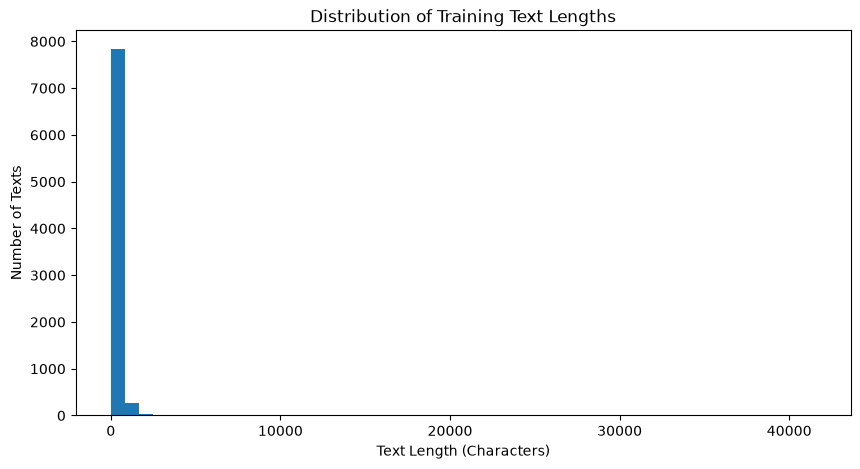

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(text_lengths, bins=50)

plt.xlabel("Text Length (Characters)")
plt.ylabel("Number of Texts")
plt.title("Distribution of Training Text Lengths");

#### The problem is that the email lengths have a very wide range:
#### - Shortest email: 2 characters.
#### - Longest email: 41,544 characters.
#### - Average email length: 369 characters.
#### That extremely long email stretches the histogram's x-axis, making most of the shorter emails appear squeezed into one large bar.

#### **A recommendation is using two plots to understand your data better.**

#### **1. Plot the full distribution using a logarithmic x-axis**
#### This allows you to see both short and very long emails without the longer emails dominating the horizontal scale.

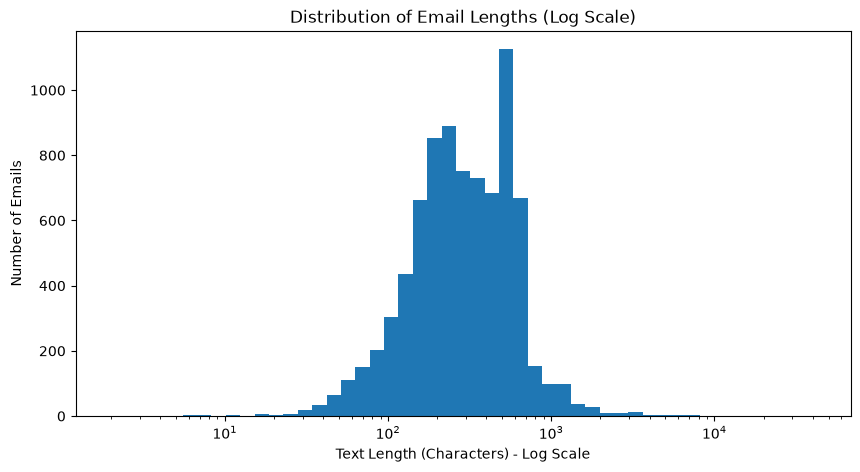

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Create logarithmically spaced bins
bins = np.logspace(
    np.log10(min(text_lengths)),
    np.log10(max(text_lengths)),
    50
)

plt.hist(text_lengths, bins=bins)

plt.xscale("log")
plt.xlabel("Text Length (Characters) - Log Scale")
plt.ylabel("Number of Emails")
plt.title("Distribution of Email Lengths (Log Scale)")

plt.show()

## **OR use:**

#### **2. Plot the distribution of most emails (recommended)**
#### We can zoom in on the first 99% of email lengths. This will make it easier to understand where most of your emails fall.

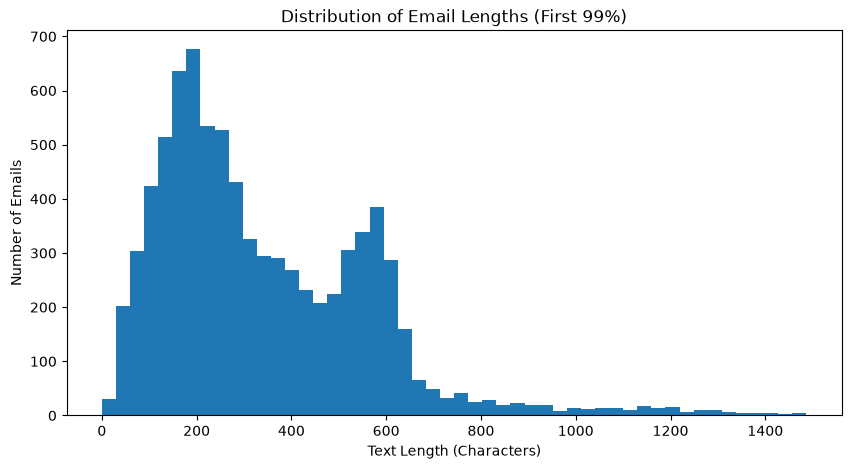

In [11]:
# Calculate the 99th percentile
percentile_99 = np.percentile(text_lengths, 99)

plt.figure(figsize=(10, 5))

plt.hist(text_lengths, bins=50, range=(0, percentile_99))

plt.xlabel("Text Length (Characters)")
plt.ylabel("Number of Emails")
plt.title("Distribution of Email Lengths (First 99%)")

plt.show()

## **Stage 2: Text preprocessing and tokenization**
#### So i added two more steps to this practice that we did not have in the original notebook
#### **A) Duplicate detection and removal**
#### - Identify exact duplicate emails.
#### - Check whether duplicate emails have conflicting labels (spam and not_spam).
#### - Remove duplicates carefully before splitting the data into training, validation and test sets.

#### **B) Text cleaning and normalization**
#### - Handle HTML tags.
#### - Handle URLs, email addresses and special characters.
#### - Handle numbers, punctuation and unusual symbols.
#### - Normalize unnecessary whitespace.
#### - Examine empty or nearly empty emails.

### **Prepare the training text**
#### First, let's extract the text column from our training dataset.

In [12]:
# Extract the text from the training dataset
train_texts = train_data["text"]

# Check the number of training texts
print("Number of training texts:", len(train_texts))

# Display the first training text
print("\nFirst training text:")
print(train_texts[0])

Number of training texts: 8175

First training text:
hey I am looking for Xray baggage datasets can you provide me with the same 


## **A) Duplicate detection and removal**
#### Let's find out how many exact dupicate emails we have:

In [13]:
import pandas as pd

# Convert training texts which is in Hugging Face Column to a pandas Series
train_texts = pd.Series(train_data["text"])

# Count the number of duplicate emails
duplicate_count = train_texts.duplicated().sum()

print("Number of duplicate emails:", duplicate_count)

Number of duplicate emails: 133


### ***Calculate the percentage of duplicate emails***

In [14]:
# Calculate the percentage of duplicate emails
duplicate_percentage = (duplicate_count / len(train_texts)) * 100

print(f"Duplicate emails: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate emails: 133
Duplicate percentage: 1.63%


### ***Investigate the emails***
#### B4 removing duplicates, here are two important things to check:
#### **a.** Are the duplicate emails carrying the same labels (spam or not_spam)?
#### **b.** Are there identical emails with conflicting labels?
#### The second situation is particularly important because it could introduce inconsistent information into our model.

### ***Step 1: Identify the duplicate emails***
#### First, let's extract all rows containing duplicate email text.

In [15]:
# Get all rows containing duplicate emails
duplicate_emails = train_data.to_pandas()
# to_pandas() converts our Hugging Face dataset into a pandas DataFrame.

# duplicated(subset=["text"], keep=False) identifies every occurrence of duplicated email
# text, including the first occurrence.
duplicate_emails = duplicate_emails[
    duplicate_emails.duplicated(subset=["text"], keep=False)
]

# Display the first 10 duplicate entries
duplicate_emails.head(10)

,text,label
27,"Hello , I am looking for dataset for vibiratio...",not_spam
102,I've written a graphical CSV file viewer and e...,not_spam
169,"Hey, where can I find data to display most pop...",not_spam
181,I'm especially looking for their demographic d...,not_spam
183,"Hello , \n\nMe and my friends are writting a p...",not_spam
190,That data sets should contain the online image...,not_spam
231,"Show off, complain, and generally have a chat ...",not_spam
416,"Hello,\n\nI work as a Category Manager more a ...",not_spam
422,"Show off, complain, and generally have a chat ...",not_spam
452,Do anybody know where can I get the power cons...,not_spam


### ***Step 2: Check for conflicting labels***

In [16]:
# Count the number of unique labels for each duplicated email
duplicate_emails.groupby("text")["label"].nunique().value_counts()
# groupby("text") groups identical email messages together.
# nunique() counts the number of different labels within each group.
# value_counts() counts how many groups have each number of unique labels.

label
1    123
Name: count, dtype: int64

#### **It means:**
#### - We have 123 duplicated email groups.
#### - Every duplicated email group has exactly one unique label.
#### - There are no conflicting labels among the duplicates.

### ***Step 3: Remove the duplicates emails***
#### Now that we've investigated them, we can safely remove the repeated entries while keeping one occurrence of each email.

In [17]:
# Remove duplicate emails, keeping the first occurrence
train_data_cleaned = train_data.to_pandas().drop_duplicates(
    subset=["text"], # subset=["text"]: Checks for duplicates based on email text.
    keep="first" # keep="first": Keeps the first occurrence and removes subsequent copies.
).reset_index(drop=True)
# reset_index(drop=True): Resets the row numbering after removal.

# Check the new dataset size
print("Original dataset size:", len(train_data))
print("Cleaned dataset size:", len(train_data_cleaned))
print("Duplicates remaining:", train_data_cleaned["text"].duplicated().sum())

Original dataset size: 8175
Cleaned dataset size: 8042
Duplicates remaining: 0


## **Another duplicates we need to investigate are those in the test dataset**

### ***Step 1: Check duplicates within the test data***

In [18]:
# Extract test email texts into a pandas Series
test_texts = pd.Series(test_data["text"])

# Count duplicate emails
test_duplicate_count = test_texts.duplicated().sum()

print("Number of duplicate emails in test data:", test_duplicate_count)

Number of duplicate emails in test data: 26


### ***Step 2: Check duplicates between training and test data***
#### We'll check whether any email in our cleaned training dataset also appears in the test dataset.

In [19]:
# Find emails appearing in both training and test data
train_test_duplicates = train_data_cleaned[
    train_data_cleaned["text"].isin(test_texts)
]

print("Number of training emails also found in test data:",
      train_test_duplicates["text"].nunique())

Number of training emails also found in test data: 79


#### **The most important finding is the 79 emails appearing in both training and test data.**
#### This means some test examples are not independent of the training data. If these emails are included in both datasets, the test evaluation may be overly optimistic.
#### **One distinction:** the 79 represents unique matching email texts, not necessarily the total number of duplicated rows.

### ***Step 3: Check whether the 79 matching emails have consistent labels***
#### Before removing anything, let's establish whether the same email has the same label in both datasets.

#### **Why is this important?**
#### Imagine an email appears as:
#### - Training: spam
#### - Test: not_spam
#### That would indicate inconsistent labelling, even though the email text is identical.

In [20]:
# Convert test data to a pandas DataFrame
test_data_df = test_data.to_pandas()

# Keep one occurrence of each email in both datasets: i.e Remove exact duplicate 
# emails within each dataset individually, keeping only the first time that email appears.
train_unique = train_data_cleaned.drop_duplicates(subset=["text"])
test_unique = test_data_df.drop_duplicates(subset=["text"])

# Match emails appearing in both datasets(i.e Identify data leakage i.e emails that 
# overlap in both train and test sets)
overlapping_emails = train_unique.merge(
    test_unique,
    on="text",
    how="inner",
    suffixes=("_train", "_test")
)

# Check whether their labels agree
label_matches = (
    overlapping_emails["label_train"] ==
    overlapping_emails["label_test"]
)

print("Total overlapping emails:", len(overlapping_emails))
print("Emails with matching labels:", label_matches.sum())
print("Emails with conflicting labels:", (~label_matches).sum())

Total overlapping emails: 79
Emails with matching labels: 79
Emails with conflicting labels: 0


#### **What should we do about the 79 overlapping emails?**
#### I recommend removing the overlapping emails from the test set, rather than the training set.

#### **Why?**
#### - We want to preserve the training data for learning.
#### - We want the test data to contain emails the model hasn't encountered during training.
#### - Removing the 79 overlapping emails helps make the test evaluation more meaningful.
#### We should also remove the 26 repeated entries within the test set, keeping one occurrence of each email.

#### **Important:** This means our original test set will become smaller. We'll record the new size so we know exactly how many independent test examples remain.

### **Step 4: Clean the test data**

In [21]:
# Remove duplicate emails within the test data
test_data_cleaned = test_data_df.drop_duplicates(
    subset=["text"],
    keep="first"
).reset_index(drop=True)

# Remove emails already present in the training data
test_data_cleaned = test_data_cleaned[
    ~test_data_cleaned["text"].isin(train_data_cleaned["text"])
].reset_index(drop=True)

# Check the results
print("Original test dataset size:", len(test_data_df))
print("Cleaned test dataset size:", len(test_data_cleaned))
print("Duplicates remaining:", test_data_cleaned["text"].duplicated().sum())

# Check for overlap with training data
print("Remaining training-test overlap:",
      test_data_cleaned["text"].isin(train_data_cleaned["text"]).sum())

Original test dataset size: 2725
Cleaned test dataset size: 2620
Duplicates remaining: 0
Remaining training-test overlap: 0


## **Another type of duplicate to check is near-duplicates**
## **Removing near-duplicates for `training data`**

#### We should check both training and test data, as well as across the two datasets.

#### **Here's why:**
#### **1.** Within training data: Near-duplicates could cause the model to see almost identical emails multiple times during learning.
#### **2.** Within test data: Near-duplicates could make some test examples redundant.
#### **3.** Across training and test data: Near-identical emails could still cause data leakage, even after removing exact duplicates.

### ***Step 1: Understand how we'll measure similarity***
#### We'll use a technique called Sequence Matching initially. Python's difflib module can compare two text strings and calculate a similarity ratio between 0 and 1.

#### **For example:**
#### - 1.0 means the texts are identical.
#### - 0.9 means they are very similar.
#### - 0.5 means they have moderate similarity.
#### - 0.0 means they have no matching sequence.
#### This is a screening technique, not a perfect definition of near-duplicates. We'll inspect the actual matching emails before deciding whether to remove anything.

#### For our dataset of 8,175 training emails, I recommend using TF-IDF with character n-grams instead of comparing every possible pair using difflib.

#### **Why?** Comparing every pair directly can be computationally expensive. TF-IDF with character n-grams is more practical for finding similar email text, including small spelling and punctuation differences.

### ***Step 2: Prepare the text for similarity checking***
#### First, let's import the tools we'll need.

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
# TfidfVectorizer: Converts email text into numerical representations based on character
# patterns.
from sklearn.neighbors import NearestNeighbors
# NearestNeighbors: Finds emails whose numerical representations are most similar.

### ***Step 3: Convert training emails into TF-IDF character n-grams***
#### **Why are we doing this?**
#### We want to identify emails that are similar even when they have small differences in spelling, punctuation or formatting.

In [23]:
# Create the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    analyzer="char", 
    # analyzer="char": Examines individual characters rather than whole words.
    ngram_range=(3, 5),
    # ngram_range=(3, 5): Extracts character sequences of 3, 4 and 5 characters.
    min_df=2
    # min_df=2: Ignores character patterns appearing in fewer than two emails.
)

# Convert training emails into numerical representations
train_tfidf = tfidf_vectorizer.fit_transform(
# fit_transform(): Learns the character patterns and converts the emails into numerical representations.
    train_data_cleaned["text"]
)

# Check the shape
print("TF-IDF matrix shape:", train_tfidf.shape)

TF-IDF matrix shape: (8042, 171459)


#### **Let's understand these numbers:**
#### - 8,042 rows: We have 8,042 unique training emails after removing exact duplicates.
#### - 171,459 columns: The vectorizer identified 171,459 different character patterns (n-grams) across the emails.
#### Each row represents an email, and each column represents a character pattern.

### ***Step 4: Find similar emails***
#### Now we'll use NearestNeighbors to find emails that are similar to one another.

In [24]:
# Create the nearest neighbors model
nearest_neighbors = NearestNeighbors(
    n_neighbors=3,
# n_neighbors=3: Finds the three closest emails for each email, including the email itself.
    metric="cosine",
# metric="cosine": Measures how similar two email representations are.
    algorithm="brute"
# algorithm="brute": Compares against all other emails to find the nearest neighbors.
)

# Fit the model on the TF-IDF matrix
nearest_neighbors.fit(train_tfidf)
# fit(): Prepares the model using our TF-IDF representations.

# Find the nearest neighbors for each email
distances, indices = nearest_neighbors.kneighbors(train_tfidf)
# kneighbors(): Finds the nearest emails and returns their distances and row indices.

# Check the shapes
print("Distances shape:", distances.shape)
print("Indices shape:", indices.shape)

Distances shape: (8042, 3)
Indices shape: (8042, 3)


#### **This means:**
#### - We have 8,042 training emails.
#### - For each email, the algorithm found 3 nearest neighbours.
#### - distances contains the cosine distances.
#### - indices contains the positions of the corresponding emails.
#### Remember, the first neighbour is normally the email itself, with a distance of 0.

### ***Step 5: Inspect the most similar emails***
#### Now let's identify emails that have at least 90% similarity, excluding each email's match with itself.

In [25]:
# Set our similarity threshold
similarity_threshold = 0.90
# similarity_threshold = 0.90: We are looking for emails with at least 90% similarity.

# Store potential near-duplicate pairs
near_duplicates = []

# Loop through every email
for i in range(len(train_data_cleaned)):
    
    # Loop through its nearest neighbors
    for j in range(1, distances.shape[1]):
# range(1, distances.shape[1]): Skips the first neighbour, which is normally the email itself.

        # Calculate similarity
        similarity = 1 - distances[i, j]
# # 1 - distances[i, j]: Converts cosine distance into similarity.

        # Check if similarity meets our threshold
        if similarity >= similarity_threshold:

            # Store the email pair and similarity score
            near_duplicates.append((
# near_duplicates.append(): Stores the positions of the two emails and their similarity score.
                i,
                indices[i, j],
                similarity
            ))

# Display the number of potential near-duplicate pairs
print("Potential near-duplicate pairs:", len(near_duplicates))

Potential near-duplicate pairs: 24


#### Good! We've found 24 potential near-duplicate pairs with at least 90% similarity.

#### However, before interpreting this number, there are two things to understand:
#### 1. The same pair might appear twice because email A can identify email B as a neighbour, and email B can identify email A.
#### 2. We asked for only 3 nearest neighbours per email, including itself. Therefore, we are checking only the two closest other emails for each email. We may be missing some additional matches.
#### Let's first inspect the 24 pairs we found.

### ***Step 6: Remove repeated pair entries***
#### The 24 matches may include the same pair twice because email A can identify email B, and email B can also identify email A. Let's remove those repeated entries.

In [26]:
# Convert potential near-duplicates into a DataFrame
near_duplicates_df = pd.DataFrame(
    near_duplicates,
    columns=["email_1", "email_2", "similarity"]
)

# Remove duplicate pairs, regardless of their order
near_duplicates_df["pair"] = near_duplicates_df.apply(
    lambda row: tuple(sorted([row["email_1"], row["email_2"]])),
    axis=1
)

near_duplicates_df = near_duplicates_df.drop_duplicates(
    subset="pair"
).drop(columns="pair")

# Sort by similarity, highest first
near_duplicates_df = near_duplicates_df.sort_values(
    by="similarity",
    ascending=False
).reset_index(drop=True)

print("Unique near-duplicate pairs:", len(near_duplicates_df))

near_duplicates_df

Unique near-duplicate pairs: 14


,email_1,email_2,similarity
0,3296,4137,0.999136
1,890,4137,0.995774
2,890,3296,0.994914
3,4195,4137,0.979448
4,4195,3296,0.978607
5,6030,7214,0.932412
6,3282,5151,0.925640
7,244,772,0.924116
8,244,7029,0.923555
9,5514,244,0.920758


### ***Step 7: Inspect the candidate emails***
#### We need to see whether these 14 pairs are genuinely similar emails or simply emails sharing common phrases.

In [27]:
near_duplicates_df = pd.DataFrame(
    near_duplicates,
    columns=["email_1", "email_2", "similarity"]
)

near_duplicates_df["pair"] = near_duplicates_df.apply(
    lambda row: tuple(sorted([row["email_1"], row["email_2"]])),
    axis=1
)
for _, row in near_duplicates_df.head(5).iterrows():
    email_1 = train_data_cleaned.iloc[int(row["email_1"])]
    email_2 = train_data_cleaned.iloc[int(row["email_2"])]

    print(f"Similarity: {row['similarity']:.3f}")
    print(f"Email 1 label: {email_1['label']}")
    print(f"Email 1: {email_1['text'][:300]}")

    print(f"Email 2 label: {email_2['label']}")
    print(f"Email 2: {email_2['text'][:300]}")

    print("-" * 80)
near_duplicates_df = near_duplicates_df.drop_duplicates(
    subset="pair"
).drop(columns="pair")

near_duplicates_df = near_duplicates_df.sort_values(
    by="similarity",
    ascending=False
).reset_index(drop=True)

print("Unique near-duplicate pairs:", len(near_duplicates_df))

near_duplicates_df

Similarity: 0.921
Email 1 label: spam
Email 1: Hey there! You won't believe what happened to me today! I stumbled upon the most fantabulous deal everrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrr. Like seriously, my mind was = 🤯🤯 when I saw it. I'm talking about the ultimate weight loss pill. Say goodbye to all those pesky pounds that have been clinging o
Email 2 label: spam
Email 2: OMG, you won't believe what I stumbled upon on this new app I found! It's literally the coolest thing everrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrr! Like, if you're not on it, what are you even doing with your life?!


--------------------------------------------------------------------------------
Similarity: 0.924
Email 1 label: not_spam
Email 1: Earlier this week, [u/EricW\_CS](https://www.reddit.com/user/EricW_CS/) posted about his [US Supreme Court transcript dataset](https://github.com/EricWiener/supreme-court-cases). 

I took the liberty of importing it into [Dolt](https://github.com/li

,email_1,email_2,similarity
0,3296,4137,0.999136
1,890,4137,0.995774
2,890,3296,0.994914
3,4195,4137,0.979448
4,4195,3296,0.978607
5,6030,7214,0.932412
6,3282,5151,0.925640
7,244,772,0.924116
8,244,7029,0.923555
9,5514,244,0.920758


#### **What should we do next?**
#### We should inspect the remaining candidate pairs, particularly those with similarity scores above 0.95, and check whether they contain the same message.

In [28]:
email_1 = train_data_cleaned.iloc[3296]["text"]
# iloc[3296] retrieves the email at row position 3296.
email_2 = train_data_cleaned.iloc[4137]["text"]

print("Are the complete emails identical:", email_1 == email_2)

Are the complete emails identical: False


#### Good. Since the result is False, the two emails are not completely identical. They are near-duplicates, not exact duplicates.

#### However, based on the earlier output, they appear to share almost all their wording. We should inspect the full messages before deciding whether they are sufficiently alike to remove one.

### ***Step 8: Inspect the remaining candidate pairs***
#### We have inspected only the first five pairs. Let's display the remaining nine, without repeating the first five.
#### We'll use the results to identify any genuine near-duplicates. We won't delete anything automatically.

In [29]:
for _, row in near_duplicates_df.iloc[5:].iterrows():
    email_1 = train_data_cleaned.iloc[int(row["email_1"])]
    email_2 = train_data_cleaned.iloc[int(row["email_2"])]

    print(f"Similarity: {row['similarity']:.3f}")
    print(f"Email 1 label: {email_1['label']}")
    print(f"Email 1: {email_1['text'][:300]}")

    print(f"Email 2 label: {email_2['label']}")
    print(f"Email 2: {email_2['text'][:300]}")

    print("-" * 80)

Similarity: 0.932
Email 1 label: not_spam
Email 1: &amp;#x200B;

Collection of the dataset that has the global list of websites built with [various e-commerce frameworks](https://www.wiredwith.com/technology/ecommerce) providing valuable insights into the market share and is an essential tool for market research and competitor analysis.

[https://ww
Email 2 label: not_spam
Email 2: Collection of the dataset that has the global list of websites built with [Magento](https://magento.com) providing valuable insights into the market share and is an essential tool for market research and competitor analysis.

&amp;#x200B;

[https://www.kaggle.com/wiredwith/websites-list/download](ht
--------------------------------------------------------------------------------
Similarity: 0.926
Email 1 label: not_spam
Email 1: Classes that I would take for it are. One major reason why I wanna do this is because it covers some General education courses I would've needed to take anyways

1. A GIS class
2. A 

#### **Interpretation of the remaining pairs**

In [30]:
near_duplicate_review = pd.DataFrame({
    "Pair / content": [
        "E-commerce websites datasets",
        "Classes to take",
        "Reddit/Dolt and supermarket datasets",
        "Master's thesis and Reddit/Dolt",
        "Weight-loss pill and new app",
        "New app and social network upgrade",
        "API endpoint and Reddit/Dolt",
        "Investment scheme"
    ],

    "Observation": [
        "Same general description, but different framework references.",
        "The displayed text is identical.",
        "Different topics; similarity is caused by shared wording.",
        "Different messages.",
        "Different spam messages with similar writing styles.",
        "Different promotional messages.",
        "Different technical messages.",
        "Almost identical messages, with only the word 'new' added."
    ],

    "Decision": [
        "Keep both",
        "Investigate as a possible duplicate",
        "Keep both",
        "Keep both",
        "Keep both",
        "Keep both",
        "Keep both",
        "Investigate as a possible near-duplicate"
    ]
})


In [31]:
pd.set_option("display.max_colwidth", None)

In [32]:
near_duplicate_review

,Pair / content,Observation,Decision
0,E-commerce websites datasets,"Same general description, but different framework references.",Keep both
1,Classes to take,The displayed text is identical.,Investigate as a possible duplicate
2,Reddit/Dolt and supermarket datasets,Different topics; similarity is caused by shared wording.,Keep both
3,Master's thesis and Reddit/Dolt,Different messages.,Keep both
4,Weight-loss pill and new app,Different spam messages with similar writing styles.,Keep both
5,New app and social network upgrade,Different promotional messages.,Keep both
6,API endpoint and Reddit/Dolt,Different technical messages.,Keep both
7,Investment scheme,"Almost identical messages, with only the word 'new' added.",Investigate as a possible near-duplicate


#### **What should we remove?**
#### For now, there are two candidates worth investigating:
#### - The identical-looking messages about classes.
#### - The two investment-scheme messages.
#### **Let's verify the first pair. The indices are 244 and 772.**
#### This checks whether the complete messages are identical, rather than just the first 300 characters.

In [33]:
email_1 = train_data_cleaned.iloc[244]["text"]
email_2 = train_data_cleaned.iloc[772]["text"]

print("Are the complete emails identical:", email_1 == email_2)

Are the complete emails identical: False


#### Good. Since the result is False, the two emails about the classes are not completely identical. They only look identical in the first 300 characters we displayed.

#### Decision: Keep both. We shouldn't remove them as duplicates.

#### Now let's verify the investment-scheme pair, which had a similarity score of 0.900.

#### **The indices are 2028 and 5637.**

In [34]:
email_1 = train_data_cleaned.iloc[2028]["text"]
email_2 = train_data_cleaned.iloc[5637]["text"]

print("Are the complete emails identical:", email_1 == email_2)

print("\nEmail 1:")
print(email_1)

print("\nEmail 2:")
print(email_2)

Are the complete emails identical: False

Email 1:
Get rich quick with our amazing investment scheme!


Email 2:
Get rich quick with our amazing new investment scheme!



#### Perfect. We have confirmed that these two emails are near-duplicates, not exact duplicates.

#### The only difference is the word "new":
#### - Email 1: Get rich quick with our amazing investment scheme!
#### - Email 2: Get rich quick with our amazing new investment scheme!
#### Both have the same label (spam) and communicate the same message.

### **Final decision on near-duplicates**
#### From our inspection:
#### - Keep emails that merely share wording or writing styles.
#### - Keep the two emails about classes because their complete contents differ.
#### - Remove one of the two investment-scheme messages.
#### **Let's remove the second email (index 5637) from the cleaned training DataFrame.**

In [35]:
train_data_cleaned = train_data_cleaned.drop(
    index=5637
).reset_index(drop=True)

print("Training dataset shape:", train_data_cleaned.shape)

Training dataset shape: (8041, 2)


### Excellent. The cleaned training dataset now contains 8,041 emails and 2 columns (text and label).
### **Let's summarise our duplicate removal:**
#### **Operation	-----------------------  Emails removed**
#### **Exact duplicates in training ---->	133**
#### **Confirmed near-duplicate in training --->	1**
#### **Total removed from training -----> 134**
#### **The original training dataset had 8,175 emails, and we now have 8,041.**

## **Removing near-duplicates for `test data`**
### ***Step 1: Convert test emails into TF-IDF features***
#### We'll reuse the tfidf_vectorizer we fitted on the training data. This is important because we want both datasets represented using the same vocabulary.

In [36]:
test_tfidf = tfidf_vectorizer.transform(
    # transform() converts the test emails into TF-IDF features.
    # We use transform(), not fit_transform(), because the vectorizer has already learned 
    # its character n-gram vocabulary from the training data.
    test_data_cleaned["text"]
)

print("TF-IDF matrix shape:", test_tfidf.shape)

TF-IDF matrix shape: (2620, 171459)


### ***Step 2: Find the nearest neighbours***
#### Now we'll find the most similar emails within the test dataset.

In [37]:
nearest_neighbors_test = NearestNeighbors(
    n_neighbors=6, # n_neighbors=6 finds six nearest neighbours for each email, including itself.
    metric="cosine", # metric="cosine" measures how similar the emails are.
    algorithm="brute"
)

nearest_neighbors_test.fit(test_tfidf)

# test_distances stores the distances between emails.
test_distances, test_indices = nearest_neighbors_test.kneighbors(test_tfidf)
# test_indices stores the positions of their nearest neighbours.

print("Distances shape:", test_distances.shape)
print("Indices shape:", test_indices.shape)

Distances shape: (2620, 6)
Indices shape: (2620, 6)


### ***Step 3: Identify potential near-duplicates***
#### We'll use the same similarity threshold of 0.90 that we used for the training dataset.

In [38]:
similarity_threshold = 0.90
test_near_duplicates = []

for i in range(len(test_data_cleaned)):
    for j in range(1, test_distances.shape[1]): 
        # We skip j = 0 because that is the email itself.
        similarity = 1 - test_distances[i, j]
        # 1 - distance converts cosine distance into cosine similarity.

        if similarity >= similarity_threshold:
            test_near_duplicates.append((
                i,
                test_indices[i, j],
                similarity
            ))

print("Potential near-duplicate pairs:", len(test_near_duplicates))

Potential near-duplicate pairs: 0


#### **Excellent! The result is: 0 potential near-duplicates**
#### This means that, using our current method (character n-grams, cosine similarity, six nearest neighbours, and a 0.90 threshold), we found no test-email pairs meeting the near-duplicate threshold.
#### What does this mean?
#### - No near-duplicate pairs were detected within the 2,620 test emails.
#### - There is nothing to remove from the test dataset based on this check.
#### - Your cleaned test dataset remains at 2,620 emails.

## **Removing near-duplicates between the training and test datasets.**
#### This is important because similar emails appearing in both datasets could affect our model evaluation.

### ***Step 1: Find the nearest training emails for each test email***
#### **We already have:**
#### - train_tfidf: TF-IDF features for the cleaned training emails.
#### - test_tfidf: TF-IDF features for the cleaned test emails.
#### - tfidf_vectorizer: fitted on the training emails.
#### This time, we will fit the nearest-neighbour search on the training data, then query it using the test data.

In [39]:
cross_neighbors = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)

cross_neighbors.fit(train_tfidf)
# fit(train_tfidf) stores the training emails as our reference dataset.

# kneighbors(test_tfidf) searches for the six most similar training emails for every test 
# email.
cross_distances, cross_indices = cross_neighbors.kneighbors(test_tfidf)
# cross_distances stores the similarity distances.
# cross_indices stores the positions of the matching training emails.

print("Distances shape:", cross_distances.shape)
print("Indices shape:", cross_indices.shape)

Distances shape: (2620, 6)
Indices shape: (2620, 6)


### ***Step 2: Identify potential near-duplicates across both datasets***
#### We'll use the same similarity threshold of 0.90. Unlike our earlier checks within a single dataset, we will examine all six neighbours because none of them is the test email itself.

In [40]:
similarity_threshold = 0.90
cross_near_duplicates = []

for i in range(len(test_data_cleaned)): # i: position of the email in the test dataset.
    for j in range(cross_distances.shape[1]):
        similarity = 1 - cross_distances[i, j]
        
        if similarity >= similarity_threshold:
            cross_near_duplicates.append((
                i,
                cross_indices[i, j],
            # cross_indices[i, j]: position of its matching email in the training dataset.
                similarity
                # similarity: how similar the two emails are.
            ))

print("Potential near-duplicate pairs:", len(cross_near_duplicates))

Potential near-duplicate pairs: 2


#### Good! We found 2 potential near-duplicate pairs between the training and test datasets.
#### This means two test emails have at least one training email with a similarity score of 0.90 or higher

### ***Step 3: Display the two candidate pairs***
#### Let's create a DataFrame to make the results easier to inspect.

In [41]:
cross_near_duplicates_df = pd.DataFrame(
    cross_near_duplicates,
    columns=["test_email", "train_email", "similarity"]
    # test_email: position of the email in the test dataset.
    # train_email: position of the matching email in the training dataset.
    # similarity: similarity score between the two emails.
)

cross_near_duplicates_df = cross_near_duplicates_df.sort_values(
    by="similarity",
    ascending=False
).reset_index(drop=True)

cross_near_duplicates_df

,test_email,train_email,similarity
0,2100,7910,0.968842
1,1442,244,0.947020


#### These are worth inspecting, but we shouldn't remove them based on similarity scores alone.

### ***Step 4: Display the actual emails***
#### Let's display both pairs and their labels.

In [42]:
for _, row in cross_near_duplicates_df.iterrows():
    test_email = test_data_cleaned.iloc[int(row["test_email"])]
    train_email = train_data_cleaned.iloc[int(row["train_email"])]

    print(f"Similarity: {row['similarity']:.3f}")

    print(f"Test label: {test_email['label']}")
    print(f"Test email:\n{test_email['text']}")

    print(f"\nTraining label: {train_email['label']}")
    print(f"Training email:\n{train_email['text']}")

    print("-" * 80)

Similarity: 0.969
Test label: not_spam
Test email:
&gt;**TL;DR:** See example notebooks below 👇

I am happy to announce that I finally finished cleaning, organizing, creating baselines, and developing an automated collection pipeline that collects minute-by-minute market data for Cryptocurrencies. It updates on Kaggle every day! And will keep doing so until the competition is over! \[Maybe even more\]

The whole project took me a lot of time to develop and is not easy to maintain, so please if you find this of value: Your feedback &amp; support is highly appreciated!

## The Competition

As some of you know, there is Crypto forecasting competition is running on Kaggle: "G-Research Crypto Forecasting". In this competition, we need to use machine learning for forecasting short-term returns of popular cryptocurrencies \[such as bitcoin, ether, dogecoin..\] We are provided a dataset of millions of rows of high-frequency market data dating back to 2018 which we should use to build our model

### Reviewing the output, I found two cross-dataset matches, but neither is a genuine near-duplicate.
### **This is the reviewing of them:**

In [43]:
import pandas as pd

comparison_table = pd.DataFrame({
    "Pair": [1, 2],
    "Test label": ["not_spam", "not_spam"],
    "Training label": ["spam", "not_spam"],
    "Observation": [
        "Completely different messages. One discusses a cryptocurrency forecasting project; the other advertises shopping deals.",
        "Both discuss Dolt and datasets, but the actual content is different."
    ],
    "Decision": ["Keep both", "Keep both"]
})

comparison_table

,Pair,Test label,Training label,Observation,Decision
0,1,not_spam,spam,Completely different messages. One discusses a cryptocurrency forecasting project; the other advertises shopping deals.,Keep both
1,2,not_spam,not_spam,"Both discuss Dolt and datasets, but the actual content is different.",Keep both


#### **Final decision**
#### Keep both test emails. We found no confirmed near-duplicates between the training and test datasets.

#### **Your datasets remain:**
#### **Dataset --------  Number of emails**
#### **Training ----->	8,041**
#### **Test -------->  2,620**

## **B) Text cleaning and normalization**

#### **The next step is checking for missing or empty email messages before we begin text cleaning and normalization.**
#### **We want to know whether any email contains:**
#### - A missing (NaN) text value.
#### - An empty string ("").
#### - Only whitespace (spaces, tabs, or newlines).
#### **Let's start with the training dataset.**

### ***1) Check for missing email text***
### Below is a fc that checks for missing email text

In [44]:
def check_email_texts(data, dataset_name):
    """
    Checks for missing, empty, and whitespace-only email messages.
    """
    # missing: counts missing text values (NaN).
    missing = data["text"].isna().sum()

    # fillna(""): temporarily replaces missing values with empty strings for checking.
    empty = (
        # str.strip(): removes surrounding whitespace for the purpose of the check
        data["text"].fillna("").str.strip() == ""
    ).sum()
    # == "": identifies empty or whitespace-only messages.
    
    print(f"{dataset_name} dataset:")
    print("Missing emails:", missing)
    print("Empty or whitespace-only emails:", empty)

#### **Use the fc**

In [45]:
check_email_texts(train_data_cleaned, "Training")
check_email_texts(test_data_cleaned, "Test")

Training dataset:
Missing emails: 0
Empty or whitespace-only emails: 0
Test dataset:
Missing emails: 0
Empty or whitespace-only emails: 0


#### **Both datasets have zero missing emails and zero empty or whitespace-only messages.We don't need to remove anything at this stage.**

### ***2) Inspect the email text before cleaning***
#### **Before writing a cleaning function, we need to understand what appears in the emails. We should inspect:**
#### 1. HTML tags.
#### 2. URLs and links.
#### 3. Email addresses.
#### 4. Special characters and punctuation.
#### 5. Numbers and currency symbols.
#### We shouldn't automatically remove these because some of them may contain useful spam indicators.
#### **Let's create a reusable function to display sample emails.**
#### **Step 1 — Create the function**

In [46]:
def display_email_samples(data, dataset_name, n=5):
    """
    Displays sample email messages for inspection.
    """
    print(f"{dataset_name} email samples:\n")

    for i in range(n):
        print(f"Email {i + 1}:")
        print(data["text"].iloc[i])
        print("-" * 80)

#### **Step 2 — Inspect both datasets**

In [47]:
display_email_samples(train_data_cleaned, "Training")
display_email_samples(test_data_cleaned, "Test")

Training email samples:

Email 1:
hey I am looking for Xray baggage datasets can you provide me with the same 
--------------------------------------------------------------------------------
Email 2:
"Get rich quick! Make millions in just days with our new and revolutionary system! Don't miss out on this amazing opportunity!"


--------------------------------------------------------------------------------
Email 3:
URGENT MESSAGE: YOU WON'T BELIEVE WHAT WE HAVE TO OFFER!!!

Hey you! Yeah, you with the eyes reading this right now. Do you want to be the coolest cat on the block? Do you want to get all the likes, hearts and emojis? Do you want to be ~*POPULAR*~? Well, we have the solution for you.

Introducing our brand new feature that will blow your mind and your feed! We can't give away too many details, but let's just say it involves puppies, unicorns, and a drum kit.

But wait, there's more! Sign up
--------------------------------------------------------------------------------
Em

#### **Here are sm things from the table:**

In [48]:
import pandas as pd

formatting_observations = pd.DataFrame({
    "Feature": [
        "HTML entities",
        "Markdown links",
        "URLs",
        "Special characters",
        "Numbers",
        "Uppercase text",
        "Escaped characters"
    ],

    "Example from your data": [
        "`&gt;`, `&amp;`",
        "`[Google AI Blog](https://...)`",
        "`https://www.deezer.com/...`",
        "`!!!`, `~`, `💰`, `🚨`",
        "`50 pounds`, `10,406,168`",
        "`GET RICH QUICK`",
        "`\\*POPULAR\\*`"
    ],

    "What we should do": [
        "Decode them into normal characters",
        "Inspect and decide how to handle them",
        "Preserve their spam-related information",
        "Don't remove blindly",
        "Preserve them",
        "Normalize consistently",
        "Handle during cleaning"
    ]
})

formatting_observations

,Feature,Example from your data,What we should do
0,HTML entities,"`&gt;`, `&amp;`",Decode them into normal characters
1,Markdown links,`[Google AI Blog](https://...)`,Inspect and decide how to handle them
2,URLs,`https://www.deezer.com/...`,Preserve their spam-related information
3,Special characters,"`!!!`, `~`, `💰`, `🚨`",Don't remove blindly
4,Numbers,"`50 pounds`, `10,406,168`",Preserve them
5,Uppercase text,`GET RICH QUICK`,Normalize consistently
6,Escaped characters,`\*POPULAR\*`,Handle during cleaning


#### **One important point: legitimate emails can also contain URLs, HTML and special characters. We shouldn't assume that these features automatically indicate spam.**

#### **Step 3 — Building our reusable text-cleaning function.**
#### We'll start with the first operation: decoding HTML entities.
#### **For example:**
#### - `&amp`; becomes &
#### - `&gt;` becomes >
#### - `&lt;` becomes <
#### **a) Import the HTML module and test it on a single email**

In [49]:
import html

# Tesyt it on a single email
sample_email = "Today &gt; September 24, 2019 &amp; Google"

html.unescape(sample_email)

'Today > September 24, 2019 & Google'

#### **Now, rather than creating a separate function for every cleaning operation, we'll gradually build one reusable clean_email() function that handles all the necessary operations.**

#### **b) Handle Markdown formatting**
#### The emails contain Markdown links like: `[Google AI Blog](https://ai.googleblog.com/...)`
#### We want to retain the readable link text (Google AI Blog) while removing the Markdown syntax and URL from that particular link. We'll preserve standalone URLs separately as useful indicators.
#### **Let's test this operation first.**

In [50]:
import re

sample_email = "[Google AI Blog](https://ai.googleblog.com/2019/09/example.html)"

cleaned_sample = re.sub(
    r"\[([^\]]+)\]\([^)]+\)",
    r"\1",
    sample_email
)

cleaned_sample

'Google AI Blog'

#### **Why this matters:** We retain the meaningful words without carrying unnecessary Markdown formatting into the model.

#### **c) Handle standalone URLs**
#### We want to preserve the information that an email contains a URL, but we don't necessarily need the full web address.
#### **For example:**
#### - https://www.example.com/offer → URL
#### - http://example.com → URL
#### This allows the model to learn that a message contains a link without treating every different web address as a completely different word.
#### **Let's test it.**

In [51]:
sample_email = "Click here: https://www.example.com/offer to claim your prize."

cleaned_sample = re.sub(
    r"https?://\S+",
    " URL ",
    sample_email
)

cleaned_sample

'Click here:  URL  to claim your prize.'

#### **d) Handle email addresses**
#### Email addresses can also be useful indicators, particularly in spam messages. We'll replace email addresses with a common token, EMAIL, rather than removing them completely.

In [52]:
sample_email = "Contact us at support@example.com for more information."

cleaned_sample = re.sub(
    r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
    " EMAIL ",
    sample_email
)

cleaned_sample

'Contact us at  EMAIL  for more information.'

#### **Why?** We preserve the fact that an email address appeared without giving the model thousands of different email addresses to learn.

#### **e) Convert text to lowercase and normalize whitespace**
#### We want words such as URGENT, Urgent and urgent to be treated as the same word. We also want to remove unnecessary spaces, tabs and line breaks.

In [53]:
sample_email = "  URGENT MESSAGE!!!   Get Your MONEY NOW!  "

cleaned_sample = sample_email.lower() # .lower() converts all letters to lowercase.
cleaned_sample = re.sub(r"\s+", " ", cleaned_sample).strip()
# re.sub(r"\s+", " ", ...) replaces consecutive whitespace characters with one space.
# .strip() removes spaces at the beginning and end.

cleaned_sample

'urgent message!!! get your money now!'

#### **f) Handle escaped characters**
#### And e.g `\*POPULAR\*`
#### These backslashes are unnecessary formatting characters. We want to remove the backslashes while retaining the asterisks and the word

In [54]:
sample_email = r"\*POPULAR\* and \~SPECIAL\~"

cleaned_sample = re.sub(r"\\", "", sample_email)

cleaned_sample

'*POPULAR* and ~SPECIAL~'

#### **g) Decode HTML entities, remove Markdown formatting, replace URLs and email addresses, lowercase, normalize whitespace and remove escape backslashes.**
#### Decode HTML entities, remove Markdown formatting, replace URLs and email addresses, lowercase, normalize whitespace and remove escape backslashes.

In [55]:
def clean_email(text):
    """
    Cleans and normalizes email text.
    """

    # Decode HTML entities
    text = html.unescape(text)

    # Remove Markdown blockquote markers
    text = re.sub(r"(?m)^\s*>\s?", "", text)

    # Remove Markdown link formatting but keep link text
    text = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", text)

    # Replace URLs
    text = re.sub(r"https?://\S+", " URL ", text)

    # Replace email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
        " EMAIL ",
        text
    )

    # Remove escape backslashes
    text = re.sub(r"\\", "", text)

    # Convert to lowercase
    text = text.lower()

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

#### **Let's test the complete function on one sample before applying it to the datasets.**

In [56]:
sample_email = (
    "URGENT! Visit [Google](https://google.com) "
    "or contact support@example.com &amp; claim \*YOUR PRIZE\*!"
)

clean_email(sample_email)

'urgent! visit google or contact email & claim *your prize*!'

#### **h) Apply the function to both datasets**
#### We're creating a new column called clean_text rather than overwriting text. This allows us to compare the original emails with their cleaned versions.

In [57]:
# Clean training email texts
train_data_cleaned["clean_text"] = train_data_cleaned["text"].apply(clean_email)

# Clean test email texts
test_data_cleaned["clean_text"] = test_data_cleaned["text"].apply(clean_email)

#### **i) Compare original and cleaned emails**
#### Let's inspect a few examples to ensure the cleaning function worked correctly on real dataset messages, not just our sample.

In [58]:
def compare_cleaned_emails(data, dataset_name, n=5):
    """
    Displays original and cleaned email texts side by side.
    """

    print(f"{dataset_name} dataset:\n")

    for i in range(n):
        print(f"Email {i + 1}")
        print("Original:")
        print(data["text"].iloc[i])

        print("\nCleaned:")
        print(data["clean_text"].iloc[i])

        print("-" * 80)

#### **Use it:**

In [59]:
compare_cleaned_emails(train_data_cleaned, "Training")
compare_cleaned_emails(test_data_cleaned, "Test")

Training dataset:

Email 1
Original:
hey I am looking for Xray baggage datasets can you provide me with the same 

Cleaned:
hey i am looking for xray baggage datasets can you provide me with the same
--------------------------------------------------------------------------------
Email 2
Original:
"Get rich quick! Make millions in just days with our new and revolutionary system! Don't miss out on this amazing opportunity!"



Cleaned:
"get rich quick! make millions in just days with our new and revolutionary system! don't miss out on this amazing opportunity!"
--------------------------------------------------------------------------------
Email 3
Original:
URGENT MESSAGE: YOU WON'T BELIEVE WHAT WE HAVE TO OFFER!!!

Hey you! Yeah, you with the eyes reading this right now. Do you want to be the coolest cat on the block? Do you want to get all the likes, hearts and emojis? Do you want to be ~*POPULAR*~? Well, we have the solution for you.

Introducing our brand new feature that will blow

#### **Overall, the cleaning function is working well, and we can move towards tokenization.**

# **Stage 3: Preparing Data for Model Training**
#### **C) Splitting training and validation data.**

#### **D) Tokenization**
#### Break each email into smaller units called tokens (words or subwords).

#### **E) Vocabulary creation**
#### Build a collection of tokens the model will recognize.

#### **F) Numerical conversion**
#### Assign integer IDs to tokens so the neural network can process them.

#### **G) Padding and truncation**
#### Make sequences the same length for batch processing

#### **H) Label encoding.**

#### **So b4 we tokenize, we need to separate our data to `training` and `validation` datasets**

### ***Step C: Create a function for splitting the data***

In [60]:
from sklearn.model_selection import train_test_split

def split_data(data, test_size=0.2, random_state=42):
    """
    Splits email data into training and validation sets.
    """

    # Separate features and labels
    X = data["clean_text"]
    y = data["label"]

    # Split the data
    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state,
        stratify=y
    )

    return X_train, X_valid, y_train, y_valid

### **Use the fc**

In [61]:
X_train, X_valid, y_train, y_valid = split_data(train_data_cleaned)

## **D) Tokenization**
#### **TensorFlow's TextVectorization layer** is what we will use for tokenization and converting our email text into numerical sequences.
#### **It performs several related tasks:**
#### 1. Tokenization: Splits each email into individual tokens (usually words).
#### 2. Vocabulary creation: Builds a collection of unique tokens from the training emails.
#### 3. Integer encoding: Assigns each token a numerical ID.
#### For example:
#### **Original email:**
#### "Get your prize now"

#### **Tokenized:**
#### ["get", "your", "prize", "now"]

#### **Integer encoded:**
#### [15, 8, 42, 6]

### ***Step 1: Create the TextVectorization layer***
#### We set max_tokens=10000 as an upper limit, not a requirement to use exactly 10,000 tokens.

In [62]:
# Create the layer
text_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=10000, # max_tokens=10000: Limits the vocabulary to a maximum of 10,000 tokens.
    output_mode="int", # output_mode="int": Converts tokens into integer IDs.
    standardize=None
    # standardize=None: Preserves our existing text formatting, including punctuation, rather 
    # than automatically stripping punctuation.
)

### ***Step 2: Adapt the TextVectorization layer***
#### **What does .adapt() do?**
#### **It examines the training emails and:**
#### 1. Identifies the individual tokens (words).
#### 2. Builds a vocabulary of the tokens it finds.
#### 3. Assigns each token an integer ID.
#### 4. Keeps the most frequent tokens, subject to our max_tokens=10000 limit.
#### **For example, if the word `free` appears frequently, it will receive an `integer ID` in the vocabulary.**

In [63]:
text_vectorizer.adapt(X_train)

## **E) Vocabulary creation**

### ***Step 1: Retrieve the vocabulary***

In [64]:
vocabulary = text_vectorizer.get_vocabulary()

print("Vocabulary size:", len(vocabulary))
print("\nFirst 20 tokens:")
print(vocabulary[:20])

Vocabulary size: 10000

First 20 tokens:
['', '[UNK]', np.str_('the'), np.str_('to'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('you'), np.str_('for'), np.str_('i'), np.str_('on'), np.str_('in'), np.str_('your'), np.str_('our'), np.str_('with'), np.str_('that'), np.str_('is'), np.str_('this'), np.str_('have'), np.str_('data')]


#### **What are we doing?**
#### - get_vocabulary() retrieves the words and tokens learned by the vectorizer.
#### - len(vocabulary) tells us how many tokens are in the vocabulary.
#### - vocabulary[:20] displays the first 20 tokens.
#### **One important detail: the first two entries are reserved for special purposes:**
#### - "" — padding.
#### - "[UNK]" — tokens that are not in the vocabulary (unknown words).
#### **The remaining tokens are arranged by frequency, from most frequent to less frequent.**

### ***Step 2: Let's examine the vocabulary size at different limits***

In [65]:
print("Total unique tokens:", len(text_vectorizer.get_vocabulary()))
print("Maximum vocabulary size:", text_vectorizer.get_config()["max_tokens"])

Total unique tokens: 10000
Maximum vocabulary size: 10000


### **Step 3: Check the full vocabulary size**
#### Let's create a temporary vectorizer without a vocabulary limit.
#### **Why are we doing this?**
#### This allows us to compare the full vocabulary against our current limit of 10,000.
#### This is only an investigation. We are not replacing our existing text_vectorizer yet.

In [66]:
full_vectorizer = tf.keras.layers.TextVectorization(
    output_mode="int",
    standardize=None
)

full_vectorizer.adapt(X_train)

print("Total unique tokens:", len(full_vectorizer.get_vocabulary()))

Total unique tokens: 34106


#### Now we know that our training emails contain 34,106 vocabulary entries, including the two special entries, while our current vectorizer retains only 10,000.

#### That means our 10,000-token limit excludes approximately 24,106 entries, mostly less frequent tokens.

### **Step 4: Examine how vocabulary frequency is distributed**

In [67]:
vocabulary_sizes = [5000, 10000, 15000, 20000, 25000, 30000, 34106]

vocabulary_comparison = pd.DataFrame({
    "Maximum vocabulary size": vocabulary_sizes
})

vocabulary_comparison["Percentage retained"] = (
    vocabulary_comparison["Maximum vocabulary size"] / 34106 * 100
).round(2)

vocabulary_comparison

,Maximum vocabulary size,Percentage retained
0,5000,14.66
1,10000,29.32
2,15000,43.98
3,20000,58.64
4,25000,73.30
5,30000,87.96
6,34106,100.00


## **F) Numerical conversion**

### ***Step 1: Convert training emails into integer sequences***

In [68]:
X_train_vectorized = text_vectorizer(X_train)

### ***Step 2: Examine the output***

In [69]:
print("Original email:")
print(X_train.iloc[0])

print("\nVectorized email:")
print(X_train_vectorized[0].numpy())

Original email:
dear all, i'm working in clinical research, all the data we collect in clinical trials are in cdisc format (sdtm and adam). now, in my free time i'm working on a personal project publicly available on github. i would use some sample data to test it but i'm not sure where to find them. do you have any idea where can i find some clinical trials data? i'm aware of how sensible are these data but there are some clinical trials which are totally publicly funded and the data should be open (like epic study). possibly they should already be in cdisc format, but in the case they are not i'll do the porting by myself. thank you all and thanks for your answer.

Vectorized email:
[1882  183   40  148   11 1890 3438   23    2   19   35  963   11 1890
 3090   25   11    1  669    1    4    1  269   11   55   67   64   40
  148   10    5  282  137  675  169   10 3913    9   45  132   39  623
   19    3  891   27   21   40   37  233   73    3   49  638   50    7
   18   33  384   73  

#### **Lets understand the output**
#### **1. Words have become integers**
#### For example, your original email begins: `dear all, i'm working in clinical research...`
#### **The vectorizer converts these words into numerical IDs:**
#### [1882, 183, 40, 148, 11, 1890, ...]

#### **2. What does 1 mean?**
#### In your output, you have several occurrences of 1.
#### Remember that index 1 represents [UNK], meaning unknown token.
#### This happens when a word is not included in our 10,000-token vocabulary.

#### **4. What do all those zeros mean?**
#### The zeros at the end represent padding.
#### Your email contains fewer tokens than the sequence length currently being used by the vectorizer. TensorFlow fills the remaining positions with zeros so that every email has the same length.

#### This is important because neural networks generally need consistently shaped input sequences.

## **G) Padding and truncation**

### ***Step 1: Let's inspect the sequence length***

In [70]:
print("Vectorized shape:", X_train_vectorized.shape)
print("Sequence length:", X_train_vectorized.shape[1])

Vectorized shape: (6432, 719)
Sequence length: 719


#### - 6432: Number of emails in our training dataset.
#### - 719: Number of positions allocated to each email.
#### This means every email has been converted into a sequence of 719 integers.

### ***Step 2: Let's check the validation data***
#### Now we need to use the same vectorizer on our validation emails.

In [71]:
X_valid_vectorized = text_vectorizer(X_valid)

In [72]:
print("Validation shape:", X_valid_vectorized.shape)

Validation shape: (1609, 792)


#### Interesting! This result reveals something important.

#### ***Your shapes are:***
#### - Training: (6432, 719)
#### - Validation: (1609, 792)
#### Notice that the sequence lengths are different: 719 versus 792.

#### ***Why did this happen?***

#### We didn't specify a fixed output_sequence_length when creating TextVectorization.

#### As a result, the vectorizer produces sequences based on the longest email in each batch of data it processes. The longest validation email is longer than the longest training email.

#### For our neural network, we want consistent input shapes across training, validation and test data.

### ***Step 3: Set a fixed sequence length***
#### Before changing anything, let's check the lengths of emails in our training data to understand what we're dealing with.

#### We want to choose a sequence length that captures most of the email content without allocating unnecessarily large sequences.

In [73]:
train_lengths = X_train.apply(lambda email: len(email.split()))

print("Longest training email:", train_lengths.max())
print("Average training email length:", round(train_lengths.mean(), 2))
print("95th percentile:", train_lengths.quantile(0.95))

Longest training email: 719
Average training email length: 60.1
95th percentile: 119.0


#### The 95th percentile means approximately 95% of training emails contain 119 tokens or fewer.
#### This tells us that most emails are relatively short, but a few are much longer.

#### **A recommendation: Use 150 tokens initially.**
#### **Why 150?**
#### - It captures more than 95% of the typical email lengths.
#### - It reduces unnecessary padding.
#### - It keeps the input sequences smaller, which is useful when training on your laptop's CPU.
#### - A small number of longer emails will be truncated, but we can evaluate whether that affects performance later.

### ***Step 4: Update our TextVectorization function***
#### Let's put the vectorizer creation into a reusable function.

In [74]:
def create_text_vectorizer(max_tokens=10000, sequence_length=150):
    """
    Creates and adapts a TextVectorization layer.
    """

    text_vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=max_tokens,
        output_mode="int",
        output_sequence_length=sequence_length,
        standardize=None
    )

    text_vectorizer.adapt(X_train)

    return text_vectorizer

#### **Setting the sequence length to 150 means emails longer than 150 tokens will be truncated, while shorter ones will be padded with zeros.**

### ***Step 5: Create our new vectorizer***

In [75]:
text_vectorizer = create_text_vectorizer(
    max_tokens=10000,
    sequence_length=150
)

#### This recreates our vectorizer with a fixed sequence length of 150 and learns its vocabulary using only X_train.

### ***Step 6: Transform training and validation emails***

In [76]:
X_train_vectorized = text_vectorizer(X_train)
X_valid_vectorized = text_vectorizer(X_valid)

### ***Step 7: Check the shapes`***

In [77]:
print("Training shape:", X_train_vectorized.shape)
print("Validation shape:", X_valid_vectorized.shape)

Training shape: (6432, 150)
Validation shape: (1609, 150)


### ***Step 8: Convert the test emails***
#### We also need to prepare our test data, but we will keep it separate for final evaluation.

In [78]:
X_test = test_data_cleaned["clean_text"]
y_test = test_data_cleaned["label"]

X_test_vectorized = text_vectorizer(X_test)

In [79]:
print("Test shape:", X_test_vectorized.shape)

Test shape: (2620, 150)


## **H) Preparing our labels OR Label encoding.**

### ***Step 1: Examine the label distribution***
#### Before converting labels into numbers, let's inspect how many spam and legitimate emails we have in each dataset.

#### **Why are we doing this?**
#### 1. To understand the distribution of spam and not_spam emails.
#### 2. To confirm both classes are represented in all three datasets.
#### 3. To help us choose the appropriate label encoding.

In [80]:
print("Training labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_valid.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Training labels:
label
spam        3299
not_spam    3133
Name: count, dtype: int64

Validation labels:
label
spam        825
not_spam    784
Name: count, dtype: int64

Test labels:
label
spam        1375
not_spam    1245
Name: count, dtype: int64


#### Good. Both classes are represented in all three datasets, and their distributions are reasonably balanced.

#### Let's interpret the training data:
#### - Spam: 3,299 emails.
#### - Not spam: 3,133 emails.
#### **This is approximately a 51.3% / 48.7% distribution. We don't have a major class imbalance problem.**

### ***2) Create a reusable label-encoding function***
#### **We'll convert:**
#### - not_spam → 0
#### - spam → 1
#### **Why use these values?** They give us a binary classification target that our neural network can learn to predict.

In [81]:
def encode_labels(labels):
    """
    Converts email labels into numerical values.
    not_spam = 0
    spam = 1
    """
    return labels.map({
        "not_spam": 0,
        "spam": 1
    })

### ***3) Encode the training, validation, and test labels***
#### **The below converts the text labels into numerical values:**
#### - not_spam → 0
#### - spam → 1
#### We need numerical labels because the neural network will learn to distinguish between the two classes using these values.

In [82]:
y_train_encoded = encode_labels(y_train)
y_valid_encoded = encode_labels(y_valid)
y_test_encoded = encode_labels(y_test)

### ***4) Verify the encoded labels***
#### Let's confirm that the conversion worked correctly.

In [83]:
print("Training labels:")
print(y_train_encoded.unique())

print("\nValidation labels:")
print(y_valid_encoded.unique())

print("\nTest labels:")
print(y_test_encoded.unique())

Training labels:
[0 1]

Validation labels:
[1 0]

Test labels:
[0 1]


#### **Excellent. All three datasets contain the correct numerical labels, 0 and 1.**

### ***5) Check the label data types***
#### Before using the labels in TensorFlow, let's confirm their data types.

In [84]:
print("Training label data type:", y_train_encoded.dtype)
print("Validation label data type:", y_valid_encoded.dtype)
print("Test label data type:", y_test_encoded.dtype)

Training label data type: int64
Validation label data type: int64
Test label data type: int64


#### Good. All three label sets have the int64 data type. That's acceptable for our binary classification task. TensorFlow can work with these integer labels, so we don't need to change their data type right now.

### ***6) Convert the labels to NumPy arrays***
#### Our text data has already been converted into numerical sequences by TextVectorization. Let's also convert the labels from pandas Series into NumPy arrays.

In [85]:
y_train_encoded = y_train_encoded.to_numpy()
y_valid_encoded = y_valid_encoded.to_numpy()
y_test_encoded = y_test_encoded.to_numpy()

#### **Why are we doing this?**
#### - Pandas Series are useful for data analysis and manipulation.
#### - NumPy arrays are convenient for passing numerical data into TensorFlow models.
#### - This gives us a consistent format for model training and evaluation.

### ***7) Check the shapes of our prepared datasets***
#### The number of emails and labels must match in each dataset.

In [86]:
print("Training data:", X_train_vectorized.shape)
print("Training labels:", y_train_encoded.shape)

print("\nValidation data:", X_valid_vectorized.shape)
print("Validation labels:", y_valid_encoded.shape)

print("\nTest data:", X_test_vectorized.shape)
print("Test labels:", y_test_encoded.shape)

Training data: (6432, 150)
Training labels: (6432,)

Validation data: (1609, 150)
Validation labels: (1609,)

Test data: (2620, 150)
Test labels: (2620,)


#### **Our prepared datasets are consistent**

### ***Finalise Stage 3***
#### Before building the model, let's create a small summary of our prepared data for documentation in the notebook.
#### This gives us a reproducible record of the data entering the modelling stage.

In [87]:
preparation_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Number of emails": [
        len(X_train_vectorized),
        len(X_valid_vectorized),
        len(X_test_vectorized)
    ],
    "Sequence length": [
        X_train_vectorized.shape[1],
        X_valid_vectorized.shape[1],
        X_test_vectorized.shape[1]
    ],
    "Number of labels": [
        len(y_train_encoded),
        len(y_valid_encoded),
        len(y_test_encoded)
    ]
})

preparation_summary

,Dataset,Number of emails,Sequence length,Number of labels
0,Training,6432,150,6432
1,Validation,1609,150,1609
2,Test,2620,150,2620


#### **So the table above is also consistent**

# **Stage 4: Building the Email Spam Identification Model**
#### We are now moving from data preparation to building our deep-learning model.
#### We'll start with an **`Embedding layer followed by a GlobalAveragePooling1D layer and Dense layers.`** This is a suitable baseline for our email text-classification task.

### ***Step 1: Understand our model architecture***
#### **1. Input layer**
#### Receives each email as a sequence of 150 integers from our TextVectorization layer.

#### **2. Embedding layer**
#### Converts each integer token into a trainable vector of numbers. Instead of treating words as unrelated numerical IDs, the model learns representations that help it recognise useful patterns.

#### **3. GlobalAveragePooling1D**
#### Takes the average of the word vectors across the sequence, producing one summary vector for each email.

#### **4. Dense layer**
#### Learns combinations of patterns that help distinguish spam from legitimate emails.

#### **5. Output layer**
#### Produces one probability between 0 and 1:
#### - Closer to 1: likely spam.
#### - Closer to 0: likely not spam.

### ***Step 2: Understand the Embedding layer parameters***
#### We will use two important parameters:

#### tf.keras.layers.Embedding(
####    input_dim=10000,
####    output_dim=128
#### )

#### **`input_dim=10000: maximum vocabulary size available to the model`.**
#### **`output_dim=128: each token will be represented by a vector of 128 numbers.`**

### ***Step 3: Build the model architecture.***

In [88]:
email_model = tf.keras.Sequential([
    # Embedding: Converts tokens into 128-dimensional vectors.
    tf.keras.layers.Embedding(
        input_dim=10000,
        output_dim=128
    ),

    # GlobalAveragePooling1D: Summarises the word representations.
    tf.keras.layers.GlobalAveragePooling1D(),
    # Dense(64): Learns patterns using 64 neurons.
    tf.keras.layers.Dense(64, activation="relu"),
    # Dense(1): Produces a spam probability using sigmoid activation.
    tf.keras.layers.Dense(1, activation="sigmoid")
])

### ***Step 4: Display the model summary***
#### This helps us understand the model's structure and how many trainable parameters it contains before training.

In [89]:
email_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ ?                           │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

#### That's normal. The model currently shows `0 parameters (unbuilt)` because Keras has not yet received an input shape to build the layers.

### ***Step 5: Build the model***
#### We need to tell the model the shape of its input: 150 tokens per email.

In [90]:
email_model.build(input_shape=(None, 150))
# None means the model can accept a variable number of emails (batch size).|
# 150 is the number of tokens in each email.

In [91]:
email_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 150, 128)            │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,288,321 (4.91 MB)

 Trainable params: 1,288,321 (4.91 MB)

 Non-trainable params: 0 (0.00 B)

#### **Understanding the summary**
#### - Embedding: 1,280,000 parameters. Learns the 128-dimensional representation for each of the 10,000 vocabulary entries.
#### - GlobalAveragePooling1D: 0 parameters. Summarises the token representations.
#### - Dense (64): 8,256 parameters. Learns patterns useful for classification.
#### - Output Dense (1): 65 parameters. Produces the spam probability.

#### **Total trainable parameters: 1,288,321.**

### ***Step 6: Compile the model***
#### We are using binary cross-entropy because our output layer has one neuron with sigmoid activation.

In [92]:
email_model.compile(
    # BinaryCrossentropy: Measures prediction errors for our two classes (spam and not_spam).
    loss=tf.keras.losses.BinaryCrossentropy(),
    # Adam: Updates the model's weights during learning.
    optimizer=tf.keras.optimizers.Adam(),
    metrics=["accuracy"] # accuracy: Measures the proportion of emails classified correctly.
)

### ***Step 7: Verify model compilation.***
#### This confirms that the Adam optimizer was successfully attached during compilation.

In [93]:
email_model.optimizer

# **Stage 5: Training the Email Spam Identification Model**
#### Now we move to training. This is where the model learns patterns from our training emails and checks its performance against the validation emails.
### ***Step 1: Train the model***
#### **We'll use:**
#### - **`X_train_vectorized:`** training emails.
#### - **`y_train_encoded:`** training labels.
#### - **`X_valid_vectorized:`** validation emails.
#### - **`y_valid_encoded:`** validation labels.
#### - **`epochs=10:`** up to 10 complete passes through the training data.
#### - **`batch_size=32:`** 32 emails per training batch.

In [1]:
# history = email_model.fit(
#     X_train_vectorized,
#     y_train_encoded,
#     epochs=10,
#     batch_size=32,
#     validation_data=(
#         X_valid_vectorized,
#         y_valid_encoded
#     ),
#     callbacks=[
#         tf.keras.callbacks.EarlyStopping(
#             monitor="val_loss",
#             patience=3,
#             restore_best_weights=True
#         ),
#         tf.keras.callbacks.ModelCheckpoint(
#             filepath="going-thru-some-parts-of-email-spam-project/models/best_email_spam_model.keras",
#             monitor="val_loss",
#             save_best_only=True,
#             mode="min"
#         )
#     ]
# )

### ***Step 2: Save the trained model***

In [95]:
# email_model.save(
#     "going-thru-some-parts-of-email-spam-project/models/email_spam_model.keras"
# )

### ***Step 3: Load the saved model***

In [96]:
email_model = tf.keras.models.load_model(
    "going-thru-some-parts-of-email-spam-project/models/email_spam_model.keras"
)

### **Step 4: Save the TextVectorization layer**
#### One important component remains to be saved: our text_vectorizer.
#### Remember, it contains the vocabulary learned from X_train. We need it to convert future emails into the same numerical format used by our model.

In [97]:
vectorizer_model = tf.keras.Sequential([
    tf.keras.Input(shape=(), dtype=tf.string),
    text_vectorizer
])

# vectorizer_model.save(
#     "going-thru-some-parts-of-email-spam-project/models/email_text_vectorizer.keras"
# )

#### ***The above code will ggive issue, bcos i have encountered this in the same project `email-spam-identification`, chatgpt helped me in processing it to be able to save well using the same process as seen below:***

In [98]:
import builtins
import io

# Preserve Python's original open function
original_builtin_open = builtins.open

# Use io.open as the underlying file-opening function
original_open = io.open

# Create a UTF-8 wrapper
def utf8_open(file, mode="r", *args, **kwargs):

    if "b" not in mode:
        kwargs.setdefault("encoding", "utf-8")

    return original_open(file, mode, *args, **kwargs)

# Temporarily override builtins.open
builtins.open = utf8_open

try:
    vectorizer_model.save(
        "going-thru-some-parts-of-email-spam-project/models/email_text_vectorizer.keras"
    )

    print("TextVectorization model saved successfully!")

finally:
    # Restore Python's original open function
    builtins.open = original_builtin_open

TextVectorization model saved successfully!


#### **So what the fc does above is to:**
#### - Preserves the original Python file-handling function.
#### - Forces text files to use UTF-8 encoding.
#### - Saves the vectorizer with its complete vocabulary, including emojis.
#### - Restores the original file-handling function.

### ***Step 5: Load the saved TextVectorization model***
#### Because we encountered the same Windows encoding issue, we'll use the UTF-8 workaround when loading it too.

In [99]:
import builtins
import io

original_builtin_open = builtins.open
original_open = io.open

def utf8_open(file, mode="r", *args, **kwargs):
    if "b" not in mode:
        kwargs.setdefault("encoding", "utf-8")

    return original_open(file, mode, *args, **kwargs)

builtins.open = utf8_open

try:
    loaded_vectorizer_model = tf.keras.models.load_model(
        "going-thru-some-parts-of-email-spam-project/models/email_text_vectorizer.keras"
    )

    print("TextVectorization model loaded successfully!")

finally:
    builtins.open = original_builtin_open

TextVectorization model loaded successfully!


### ***Step 6: Verify the loaded vectorizer***
#### This checks that the saved vectorizer works independently of the original training notebook.

In [100]:
sample_email = tf.constant([
    "Congratulations! You have won a prize. Claim your reward now!"
])

sample_vectorized = loaded_vectorizer_model(sample_email)

print("Vectorized shape:", sample_vectorized.shape)
print("Vectorized output:")
print(sample_vectorized)

Vectorized shape: (1, 150)
Vectorized output:
tf.Tensor(
[[   1    1   18 2124    5 5785    1   12 7023  171    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0]], shape=(1, 150), dtype=int64)


### ***Step 7: we'll test the complete saved pipeline: pass the vectorized email into the reloaded spam classifier and obtain its prediction.***

In [101]:
prediction = email_model.predict(sample_vectorized)

print("Spam probability:", prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
Spam probability: 0.84468144


#### Good. The model returned a spam probability of 0.9322, or approximately 93.22%.

#### This means the classifier considers the sample email highly likely to be spam.

#### Because our label encoding is:
#### - 0 = not_spam
#### - 1 = spam
#### A probability above 0.5 is classified as spam using the default threshold.

#### One important point: this is a prediction from the currently loaded email_model. If you have since retrained the model with callbacks, make sure you use the retrained model before treating this as the final result.

### ***Step: 8 Convert the probability into a readable prediction***

In [102]:
predicted_label = "spam" if prediction[0][0] >= 0.5 else "not_spam"

print("Predicted label:", predicted_label)

Predicted label: spam


### ***Step 9: Test with a legitimate email***
#### Let's see how the model handles an email that should be legitimate.

In [103]:
sample_email = tf.constant([
    "Hi John, please find attached the meeting notes from our discussion yesterday. Let me know if you have any questions."
])

sample_vectorized = loaded_vectorizer_model(sample_email)

prediction = email_model.predict(sample_vectorized)

predicted_label = "spam" if prediction[0][0] >= 0.5 else "not_spam"

print("Spam probability:", prediction[0][0])
print("Predicted label:", predicted_label)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Spam probability: 0.060100436
Predicted label: not_spam


#### The legitimate email was correctly classified as not_spam, with a spam probability of approximately 6.01%.

# **Stage 6 — Model Evaluation.**
### ***Step 1: Evaluate on the test dataset***

In [104]:
test_loss, test_accuracy = email_model.evaluate(
    X_test_vectorized,
    y_test_encoded
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9947 - loss: 0.0175
Test loss: 0.017488082870841026
Test accuracy: 0.994656503200531


#### **Conclusion**
#### The trained email spam classification model achieved a test accuracy of 99.47% and a test loss of 0.0175 on the unseen test dataset. This indicates that the model learned to distinguish between spam and legitimate emails with very high accuracy.

#### The low test loss further suggests that the model's predictions were generally confident and consistent with the true labels.

#### Overall, the results demonstrate that the developed deep learning model performs very well on the test dataset and provides a strong foundation for practical email spam classification. However, further testing with independently collected real-world emails will be necessary to establish how well it generalizes to emails outside the original dataset.

### ***`One recommendation before using it on real emails:` preserve the exact preprocessing and vectorization pipeline used during training. Don't independently adapt the vectorizer on new emails. New emails must go through the same cleaning process and saved vectorizer before classification.***

### ***Also, keep collecting real spam and legitimate emails, with reliable labels. That will help you build a more representative dataset and test how well the model generalizes beyond the original dataset.***